# Healthcare Quality Measure Analysis — Synthetic Claims Data
### Analyst I Portfolio Project (HSAG-style workflow)

**Objective.** Calculate and evaluate a HEDIS-style quality measure, **HbA1c Testing for Members with Diabetes**, from synthetic administrative data, compare two measurement years, assess **equity disparities**, and document every quality-control step.

**Workflow demonstrated (mapped to the Analyst I responsibilities):**

| Step | Section | Responsibility |
|---|---|---|
| Understand data sources and limitations | 1 | Eligibility, medical claims, pharmacy claims, survey |
| Relational database and structured queries | 2 | SQL joins, aggregation, recoding in SQLite |
| Quality-control review | 3 | Record counts, frequencies, reasonableness checks, reconciliation |
| Apply established analytic methods | 4-5 | Measure specification, Wilson CIs, z-test, chi-square, logistic regression |
| Tables, charts, deliverables | 6 | Static PNG figures saved to `PIC/` (10 figures) |
| Predictive modeling with neural networks | 7 | PyTorch MLP deep ensemble vs logistic and boosting baselines, calibration, fairness audit |
| Reproducible documentation | 8 | Data dictionary, specification, model card, assumptions, SAS equivalents |

All data are **synthetic**. No real patient information is used.


In [41]:
import os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

os.makedirs("PIC", exist_ok=True)
rng = np.random.default_rng(2024)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


## 1. Source Data (synthetic)

Four source tables, kept separate as in real health-plan data:

- **eligibility** — one row per member per year: months enrolled, longest coverage gap, plan type
- **medical_claims** — diagnosis (ICD-10) and procedure (CPT) codes with paid amount
- **pharmacy_claims** — fills by drug class
- **survey** — CAHPS-style 0-10 rating of health plan

Known data problems are injected on purpose (duplicates, orphan claims, impossible dates, negative payments, missing IDs) so the QC section has real work to do.


In [42]:
N = 40000
members = pd.DataFrame({
    "member_id": [f"M{i:06d}" for i in range(N)],
    "birth_year": rng.integers(1945, 2006, N),
    "sex": rng.choice(["F", "M"], N, p=[0.54, 0.46]),
    "race_ethnicity": rng.choice(
        ["White", "Black", "Hispanic", "Asian", "Other"], N, p=[0.48, 0.20, 0.22, 0.06, 0.04]),
})

# Eligibility: member-year table for 2023 and 2024
elig_rows = []
for y in (2023, 2024):
    keep = rng.random(N) < 0.93
    for mid, k in zip(members.member_id, keep):
        if not k:
            continue
        months = int(np.clip(rng.choice([12]*9 + [11, 9, 6, 3]), 1, 12))
        gap = int(rng.choice([0, 0, 0, 0, 20, 40, 60]))
        plan = rng.choice(["Commercial", "Medicaid", "Medicare"], p=[0.45, 0.35, 0.20])
        elig_rows.append((mid, y, months, gap, plan))
eligibility = pd.DataFrame(elig_rows, columns=["member_id", "year", "months_enrolled", "max_gap_days", "plan_type"])

# True diabetes status (hidden) drives claims
age_2024 = 2024 - members.birth_year
p_diab = np.clip(0.05 + 0.0030 * (age_2024 - 18), 0.03, 0.30)
members["has_diabetes"] = rng.random(N) < p_diab
members["engagement"] = rng.normal(0, 1, N)   # latent care-seeking propensity (hidden from analyst)

med = []
def add(mid, y, dx, cpt, paid):
    d = pd.Timestamp(f"{y}-01-01") + pd.Timedelta(days=int(rng.integers(0, 365)))
    med.append((mid, d, dx, cpt, round(float(paid), 2)))

mm = members.merge(eligibility, on="member_id")
for r in mm.itertuples():
    y = r.year
    if r.has_diabetes:
        for _ in range(1 + rng.poisson(max(0.3, 2.0 + 0.8 * r.engagement))):
            add(r.member_id, y, "E11.9", "99213", rng.gamma(2, 60))
        # HbA1c test probability: improves over time, varies by plan and race
        p = 0.62 + 0.06 * (y == 2024)
        p += {"Commercial": 0.08, "Medicare": 0.04, "Medicaid": -0.07}[r.plan_type]
        p += {"White": 0.0, "Black": -0.06, "Hispanic": -0.04, "Asian": 0.02, "Other": -0.02}[r.race_ethnicity]
        p += 0.15 * r.engagement
        if rng.random() < np.clip(p, 0.2, 0.95):
            add(r.member_id, y, "E11.9", "83036", rng.gamma(2, 12))
    else:
        for _ in range(rng.integers(0, 4)):
            add(r.member_id, y, rng.choice(["I10", "J06.9", "M54.5", "Z00.00"]), "99213", rng.gamma(2, 55))
        if rng.random() < 0.05:      # non-diabetic screening tests exist too
            add(r.member_id, y, "Z13.1", "83036", rng.gamma(2, 12))

medical_claims = pd.DataFrame(med, columns=["member_id", "service_date", "dx_code", "cpt_code", "paid_amount"])
medical_claims.insert(0, "claim_id", [f"C{i:08d}" for i in range(len(medical_claims))])

# Pharmacy claims: diabetes drugs for ~60% of diabetic members
rx = []
for r in members[members.has_diabetes].itertuples():
    if rng.random() < 0.6:
        for y in (2023, 2024):
            for _ in range(rng.integers(2, 8)):
                d = pd.Timestamp(f"{y}-01-01") + pd.Timedelta(days=int(rng.integers(0, 365)))
                rx.append((r.member_id, d, rng.choice(["Metformin", "Insulin", "GLP1"], p=[0.6, 0.25, 0.15])))
pharmacy_claims = pd.DataFrame(rx, columns=["member_id", "fill_date", "drug_class"])

# Survey: 0-10 plan rating, correlated with plan type
sv = members.sample(3000, random_state=3)[["member_id"]].copy()
sv = sv.merge(eligibility[eligibility.year == 2024][["member_id", "plan_type"]], on="member_id")
sv["plan_rating"] = np.clip(np.round(rng.normal(8.0, 1.6, len(sv)) + sv.plan_type.map(
    {"Commercial": 0.3, "Medicare": 0.4, "Medicaid": -0.5}).values), 0, 10).astype(int)
survey = sv

# Inject known data-quality problems
dups = medical_claims.sample(60, random_state=1)
medical_claims = pd.concat([medical_claims, dups], ignore_index=True)                      # duplicate claims
orphans = medical_claims.sample(40, random_state=2).copy()
orphans["member_id"] = [f"X{i:05d}" for i in range(40)]
orphans["claim_id"] = [f"CORPH{i:04d}" for i in range(40)]
medical_claims = pd.concat([medical_claims, orphans], ignore_index=True)                   # orphan claims
medical_claims.loc[medical_claims.sample(25, random_state=4).index, "service_date"] = pd.Timestamp("2031-06-15")  # future dates
medical_claims.loc[medical_claims.sample(30, random_state=5).index, "paid_amount"] *= -1  # negative payments
medical_claims.loc[medical_claims.sample(15, random_state=6).index, "member_id"] = None   # missing IDs

for name, d in [("members", members), ("eligibility", eligibility), ("medical_claims", medical_claims),
                ("pharmacy_claims", pharmacy_claims), ("survey", survey)]:
    print(f"{name:16s} {d.shape}")
medical_claims.head()


members          (40000, 6)
eligibility      (74407, 5)
medical_claims   (138338, 6)
pharmacy_claims  (31398, 3)
survey           (2793, 3)


,claim_id,member_id,service_date,dx_code,cpt_code,paid_amount
0,C00000000,M000000,2023-03-11,M54.5,99213,30.24
1,C00000001,M000000,2023-03-02,Z00.00,99213,213.39
2,C00000002,M000000,2024-08-11,M54.5,99213,77.68
3,C00000003,M000001,2023-09-09,I10,99213,78.08
4,C00000004,M000001,2023-09-07,I10,99213,34.46


## 2. Relational Database and SQL

Tables are loaded into an in-memory SQLite database. Cohort building is done with SQL, the way it would be done against a warehouse.


In [43]:
con = sqlite3.connect(":memory:")
members.drop(columns=["has_diabetes", "engagement"]).to_sql("members", con, index=False)   # truth flag is NOT available to the analyst
eligibility.to_sql("eligibility", con, index=False)
mc = medical_claims.copy(); mc["service_date"] = mc["service_date"].astype(str)
mc.to_sql("medical_claims", con, index=False)
pc = pharmacy_claims.copy(); pc["fill_date"] = pc["fill_date"].astype(str)
pc.to_sql("pharmacy_claims", con, index=False)
survey.to_sql("survey", con, index=False)

def q(sql):
    return pd.read_sql_query(sql, con)

# Clean claims view: remove duplicates, missing IDs, negative paid, out-of-range dates, orphan members
con.executescript('''
DROP VIEW IF EXISTS claims_clean;
CREATE VIEW claims_clean AS
SELECT DISTINCT c.claim_id, c.member_id, c.service_date, c.dx_code, c.cpt_code, c.paid_amount,
       CAST(substr(c.service_date,1,4) AS INTEGER) AS svc_year
FROM medical_claims c
JOIN members m ON m.member_id = c.member_id
WHERE c.member_id IS NOT NULL
  AND c.paid_amount >= 0
  AND c.service_date BETWEEN '2023-01-01' AND '2024-12-31';
''')
q("SELECT COUNT(*) AS clean_claims FROM claims_clean")


,clean_claims
0,138168


In [44]:
# Measure cohort in SQL: one row per member-year
cohort_sql = '''
WITH dx AS (   -- diabetes: >=2 claims with E11 on different dates in the year, OR a diabetes drug fill
    SELECT member_id, svc_year AS year
    FROM claims_clean
    WHERE dx_code LIKE 'E11%'
    GROUP BY member_id, svc_year
    HAVING COUNT(DISTINCT service_date) >= 2
),
rx AS (
    SELECT member_id, CAST(substr(fill_date,1,4) AS INTEGER) AS year
    FROM pharmacy_claims
    GROUP BY member_id, year
),
dm AS (
    SELECT member_id, year FROM dx UNION SELECT member_id, year FROM rx
),
tests AS (
    SELECT member_id, svc_year AS year, 1 AS hba1c_test
    FROM claims_clean WHERE cpt_code = '83036'
    GROUP BY member_id, svc_year
)
SELECT e.member_id, e.year, e.plan_type, e.months_enrolled, e.max_gap_days,
       (e.year - m.birth_year) AS age, m.sex, m.race_ethnicity,
       CASE WHEN dm.member_id IS NOT NULL THEN 1 ELSE 0 END AS diabetes,
       COALESCE(t.hba1c_test, 0) AS hba1c_test
FROM eligibility e
JOIN members m ON m.member_id = e.member_id
LEFT JOIN dm    ON dm.member_id = e.member_id AND dm.year = e.year
LEFT JOIN tests t ON t.member_id = e.member_id AND t.year = e.year
'''
cohort_all = q(cohort_sql)
cohort_all.head()


,member_id,year,plan_type,months_enrolled,max_gap_days,age,sex,race_ethnicity,diabetes,hba1c_test
0,M000000,2023,Medicare,12,0,64,F,White,0,0
1,M000001,2023,Medicare,12,20,37,M,White,0,0
2,M000002,2023,Commercial,6,0,73,M,White,0,0
3,M000003,2023,Medicare,6,0,65,M,Black,0,1
4,M000004,2023,Medicaid,3,60,59,F,White,0,1


## 3. Quality-Control Review

Checks performed **before** any rate is reported: record counts, null and duplicate checks, reasonableness ranges, reconciliation of the denominator waterfall, and cross-reference of the SQL result against an independent pandas calculation.


In [45]:
qc = []
def log(check, result, status):
    qc.append({"check": check, "result": result, "status": status})

# 1. Record counts
log("medical_claims raw rows", len(medical_claims), "INFO")
log("claims_clean rows", int(q("SELECT COUNT(*) n FROM claims_clean").n[0]), "INFO")

# 2. Source-data defects
n_dup = int(medical_claims.duplicated().sum())
n_null = int(medical_claims.member_id.isna().sum())
n_neg = int((medical_claims.paid_amount < 0).sum())
n_future = int((medical_claims.service_date > "2024-12-31").sum())
n_orph = int((~medical_claims.member_id.dropna().isin(members.member_id)).sum())
for name, n in [("duplicate claim rows", n_dup), ("missing member_id", n_null),
                ("negative paid_amount", n_neg), ("service_date after 2024", n_future),
                ("orphan claims (member not in roster)", n_orph)]:
    log(name, n, "FLAG" if n else "PASS")

# 3. Reasonableness checks
age_ok = cohort_all.age.between(0, 110).all()
log("age within 0-110", bool(age_ok), "PASS" if age_ok else "FLAG")
months_ok = cohort_all.months_enrolled.between(1, 12).all()
log("months_enrolled within 1-12", bool(months_ok), "PASS" if months_ok else "FLAG")
log("diabetes prevalence 2024 (all members)", f"{cohort_all[cohort_all.year==2024].diabetes.mean():.1%}", "INFO")

# 4. Frequency review
print("Plan type frequency:"); print(cohort_all.plan_type.value_counts(normalize=True).round(3).to_string())
print("\nRace/ethnicity frequency:"); print(cohort_all.race_ethnicity.value_counts(normalize=True).round(3).to_string())

pd.DataFrame(qc)


Plan type frequency:
plan_type
Commercial    0.449
Medicaid      0.350
Medicare      0.201

Race/ethnicity frequency:
race_ethnicity
White       0.484
Hispanic    0.218
Black       0.200
Asian       0.058
Other       0.041


,check,result,status
0,medical_claims raw rows,138338,INFO
1,claims_clean rows,138168,INFO
2,duplicate claim rows,60,FLAG
3,missing member_id,15,FLAG
4,negative paid_amount,30,FLAG
5,service_date after 2024,25,FLAG
6,orphan claims (member not in roster),40,FLAG
7,age within 0-110,True,PASS
8,months_enrolled within 1-12,True,PASS
9,diabetes prevalence 2024 (all members),14.1%,INFO


In [46]:
# Denominator waterfall with specification: age 18-75, diabetes, continuous enrollment
# (>=11 months enrolled, max gap <=45 days)
def build_denominator(c):
    steps = {}
    steps["1. Eligibility member-years"] = len(c)
    c = c[c.age.between(18, 75)];                         steps["2. Age 18-75"] = len(c)
    c = c[c.diabetes == 1];                               steps["3. Diabetes identified"] = len(c)
    c = c[(c.months_enrolled >= 11) & (c.max_gap_days <= 45)]; steps["4. Continuously enrolled"] = len(c)
    return c, steps

waterfall = {}
denoms = {}
for y in (2023, 2024):
    d, s = build_denominator(cohort_all[cohort_all.year == y])
    denoms[y] = d; waterfall[y] = s
wf = pd.DataFrame(waterfall); wf.index.name = "step"
print(wf.to_string())

# Independent verification: re-derive 2024 denominator in pandas, compare to SQL
chk = cohort_all[(cohort_all.year == 2024) & cohort_all.age.between(18, 75) & (cohort_all.diabetes == 1)
                 & (cohort_all.months_enrolled >= 11) & (cohort_all.max_gap_days <= 45)]
assert len(chk) == len(denoms[2024]), "Reconciliation FAILED"
print("\nReconciliation PASS: independent count equals waterfall step 4 for 2024 (n =", len(chk), ")")

# Reasonableness: numerator cannot exceed denominator
for y in (2023, 2024):
    assert denoms[y].hba1c_test.sum() <= len(denoms[y])
print("Reasonableness PASS: numerator <= denominator in both years")


                              2023   2024
step                                     
1. Eligibility member-years  37258  37149
2. Age 18-75                 35469  34776
3. Diabetes identified        4792   4672
4. Continuously enrolled      3127   3065

Reconciliation PASS: independent count equals waterfall step 4 for 2024 (n = 3065 )
Reasonableness PASS: numerator <= denominator in both years


## 4. Measure Results with Confidence Intervals

**Measure:** HbA1c testing rate = members with at least one HbA1c test (CPT 83036) in the year / eligible diabetic members. Rates use **Wilson 95% confidence intervals**. Year-over-year change is tested with a **two-proportion z-test**.


In [47]:
rows = []
for y in (2023, 2024):
    d = denoms[y]
    x, n = int(d.hba1c_test.sum()), len(d)
    lo, hi = proportion_confint(x, n, alpha=0.05, method="wilson")
    rows.append({"year": y, "numerator": x, "denominator": n, "rate": x / n, "ci_low": lo, "ci_high": hi})
rates = pd.DataFrame(rows)
print(rates.assign(rate=lambda t: t.rate.map("{:.1%}".format),
                   ci_low=lambda t: t.ci_low.map("{:.1%}".format),
                   ci_high=lambda t: t.ci_high.map("{:.1%}".format)).to_string(index=False))

z, p = proportions_ztest(rates.numerator.values, rates.denominator.values)
diff = rates.rate[1] - rates.rate[0]
print(f"\nChange 2023 -> 2024: {diff*100:+.1f} percentage points, z = {z:.2f}, p = {p:.4f}")


 year  numerator  denominator  rate ci_low ci_high
 2023       2043         3127 65.3%  63.6%   67.0%
 2024       2148         3065 70.1%  68.4%   71.7%

Change 2023 -> 2024: +4.7 percentage points, z = -3.99, p = 0.0001


## 5. Equity Analysis

Rates by race/ethnicity and plan type for 2024, a chi-square test of independence, and a **logistic regression** adjusting for age, sex, plan type, and race/ethnicity. Results are reported as odds ratios with 95% CIs.


In [48]:
d24 = denoms[2024].copy()

def group_rates(df, col):
    out = df.groupby(col).hba1c_test.agg(x="sum", n="count").reset_index()
    ci = [proportion_confint(r.x, r.n, method="wilson") for r in out.itertuples()]
    out["rate"] = out.x / out.n
    out["ci_low"] = [c[0] for c in ci]; out["ci_high"] = [c[1] for c in ci]
    return out

by_race = group_rates(d24, "race_ethnicity")
by_plan = group_rates(d24, "plan_type")
print(by_race.round(3).to_string(index=False)); print()
print(by_plan.round(3).to_string(index=False))

for col in ("race_ethnicity", "plan_type"):
    ct = pd.crosstab(d24[col], d24.hba1c_test)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f"\nChi-square, test rate by {col}: chi2 = {chi2:.2f}, df = {dof}, p = {p:.4f}")


race_ethnicity    x    n  rate  ci_low  ci_high
         Asian  150  199 0.754   0.689    0.808
         Black  374  607 0.616   0.577    0.654
      Hispanic  488  691 0.706   0.671    0.739
         Other  105  130 0.808   0.732    0.866
         White 1031 1438 0.717   0.693    0.740

 plan_type    x    n  rate  ci_low  ci_high
Commercial 1052 1380 0.762   0.739    0.784
  Medicaid  664 1072 0.619   0.590    0.648
  Medicare  432  613 0.705   0.667    0.739

Chi-square, test rate by race_ethnicity: chi2 = 32.38, df = 4, p = 0.0000

Chi-square, test rate by plan_type: chi2 = 58.83, df = 2, p = 0.0000


In [49]:
d24["age_10yr"] = d24.age / 10
model = smf.logit(
    "hba1c_test ~ age_10yr + C(sex) + C(plan_type, Treatment('Commercial')) + C(race_ethnicity, Treatment('White'))",
    data=d24).fit(disp=0)

res = pd.DataFrame({"OR": np.exp(model.params),
                    "CI_low": np.exp(model.conf_int()[0]),
                    "CI_high": np.exp(model.conf_int()[1]),
                    "p": model.pvalues}).drop("Intercept")
res.index = (res.index.str.replace(r"C\((.*?)(,.*?)?\)\[T\.", r"\1: ", regex=True).str.replace("]", "", regex=False))
print(res.round(3).to_string())
print(f"\nn = {int(model.nobs)}, pseudo R-squared = {model.prsquared:.3f}")


                             OR  CI_low  CI_high      p
sex: M                    1.028   0.878    1.204  0.731
plan_type: Medicaid       0.506   0.425    0.604  0.000
plan_type: Medicare       0.735   0.593    0.911  0.005
race_ethnicity: Asian     1.198   0.848    1.692  0.306
race_ethnicity: Black     0.621   0.507    0.760  0.000
race_ethnicity: Hispanic  0.917   0.749    1.122  0.401
race_ethnicity: Other     1.605   1.019    2.529  0.041
age_10yr                  0.977   0.929    1.028  0.377

n = 3065, pseudo R-squared = 0.025


## 6. Deliverables: Tables and Figures

Every chart is saved as a static PNG in the `PIC/` folder for the repository README.


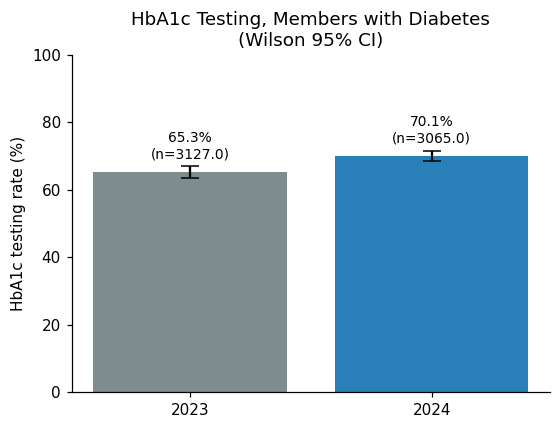

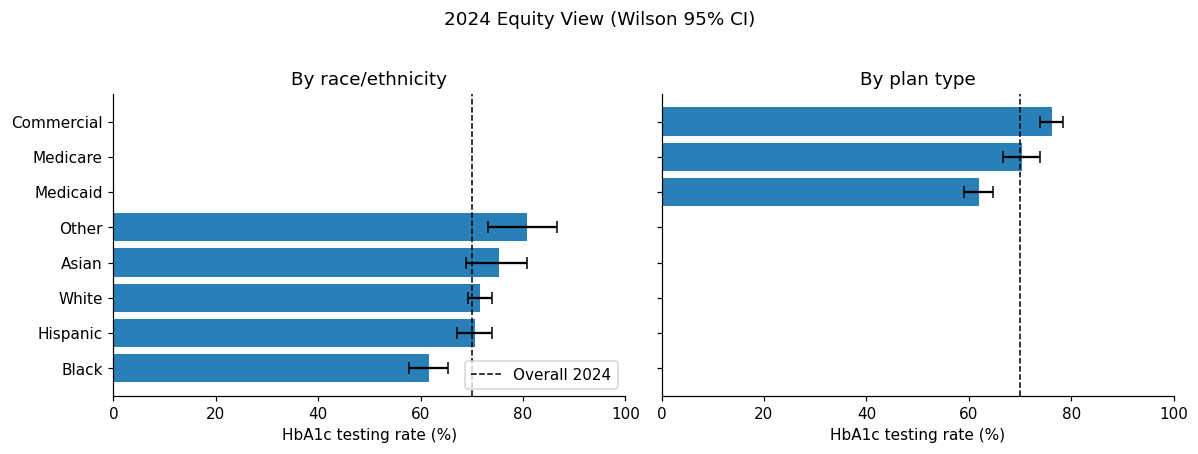

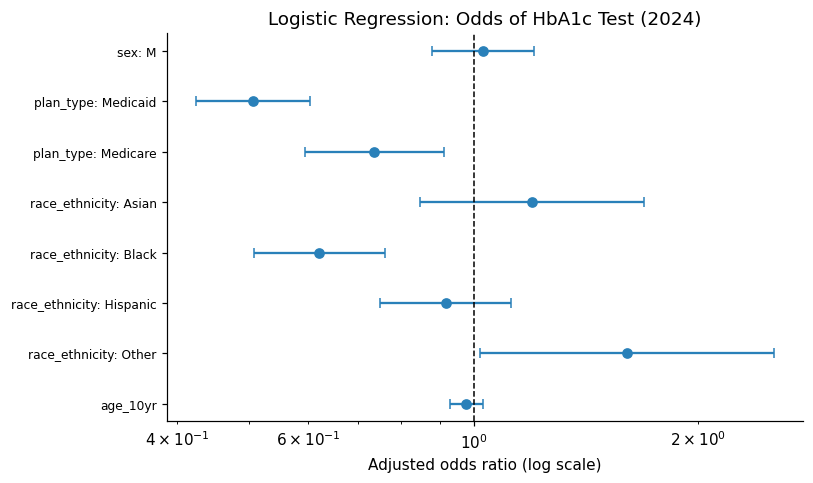

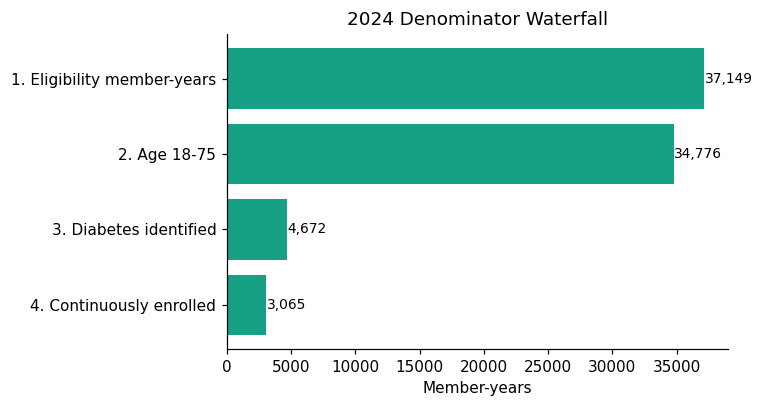

Saved: ['01_hba1c_rate_by_year.png', '02_equity_by_group.png', '03_forest_plot_odds_ratios.png', '04_denominator_waterfall.png', '05_roc_pr_curves.png', '06_mlp_training_curves.png', '07_calibration.png', '08_cumulative_gains.png', '09_fairness_audit.png', '10_permutation_importance.png']


In [50]:
# Figure 1: rate by year with 95% CI
fig, ax = plt.subplots(figsize=(5.2, 4))
ax.bar(rates.year.astype(str), rates.rate * 100, color=["#7f8c8d", "#2980b9"],
       yerr=[(rates.rate - rates.ci_low) * 100, (rates.ci_high - rates.rate) * 100], capsize=6)
for i, r in rates.iterrows():
    ax.text(i, r.rate * 100 + 4, f"{r.rate:.1%}\n(n={r.denominator})", ha="center", fontsize=9)
ax.set_ylim(0, 100); ax.set_ylabel("HbA1c testing rate (%)")
ax.set_title("HbA1c Testing, Members with Diabetes\n(Wilson 95% CI)")
plt.tight_layout(); plt.savefig("PIC/01_hba1c_rate_by_year.png"); plt.show()

# Figure 2: disparities by race/ethnicity and plan type
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, df, col, title in [(axes[0], by_race, "race_ethnicity", "By race/ethnicity"),
                           (axes[1], by_plan, "plan_type", "By plan type")]:
    df = df.sort_values("rate")
    ax.barh(df[col], df.rate * 100, color="#2980b9",
            xerr=[(df.rate - df.ci_low) * 100, (df.ci_high - df.rate) * 100], capsize=4)
    ax.axvline(rates.rate[1] * 100, color="k", ls="--", lw=1, label="Overall 2024")
    ax.set_title(title); ax.set_xlabel("HbA1c testing rate (%)"); ax.set_xlim(0, 100)
axes[0].legend(loc="lower right")
plt.suptitle("2024 Equity View (Wilson 95% CI)", y=1.02)
plt.tight_layout(); plt.savefig("PIC/02_equity_by_group.png", bbox_inches="tight"); plt.show()

# Figure 3: forest plot of adjusted odds ratios
fr = res.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.errorbar(fr.OR, range(len(fr)), xerr=[fr.OR - fr.CI_low, fr.CI_high - fr.OR], fmt="o", color="#2980b9", capsize=3)
ax.axvline(1, color="k", ls="--", lw=1)
ax.set_yticks(range(len(fr))); ax.set_yticklabels(fr.index, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Adjusted odds ratio (log scale)")
ax.set_title("Logistic Regression: Odds of HbA1c Test (2024)")
plt.tight_layout(); plt.savefig("PIC/03_forest_plot_odds_ratios.png"); plt.show()

# Figure 4: denominator waterfall
fig, ax = plt.subplots(figsize=(7, 3.8))
w = wf[2024]
ax.barh(w.index[::-1], w.values[::-1], color="#16a085")
for i, v in enumerate(w.values[::-1]):
    ax.text(v + 20, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("2024 Denominator Waterfall"); ax.set_xlabel("Member-years")
plt.tight_layout(); plt.savefig("PIC/04_denominator_waterfall.png"); plt.show()

print("Saved:", sorted(os.listdir("PIC")))


## 7. Predictive Modeling: Neural Network for Gap-in-Care Risk

**Question.** Using only *prior-year* (2023) information, can we identify diabetic members who will **miss their HbA1c test in 2024**, early enough to prioritize outreach?

**Design (what makes this defensible rather than a demo):**
- **Prediction target:** `gap = no HbA1c test in 2024`. **Features** come only from 2023 history and static plan attributes, so there is no information leakage from the outcome year.
- **Race/ethnicity is excluded from the model inputs** and used only for a post-hoc **fairness audit** (subgroup discrimination, calibration, error rates).
- **Three models, one split:** regularized logistic regression (interpretable baseline), histogram gradient boosting (strong tabular baseline), and a **PyTorch multilayer perceptron** (batch normalization, dropout, AdamW weight decay, early stopping) averaged over 5 seeds as a **deep ensemble**.
- **Evaluation:** ROC-AUC with bootstrap 95% CI, PR-AUC, Brier score, calibration curves with isotonic recalibration, decision-oriented **cumulative gains**, and permutation importance.

A neural network is not assumed to win. If it does not beat the simpler baselines, that is the finding.


In [51]:
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss, roc_curve, precision_recall_curve

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)


torch 2.6.0+cpu | device: cpu


In [52]:
# Feature engineering in SQL: 2023 history for members who are diabetic in 2024
hist_sql = '''
SELECT m.member_id,
       COALESCE(h.n_claims_py, 0)  AS n_claims_py,
       COALESCE(h.n_visits_py, 0)  AS n_visits_py,
       COALESCE(h.n_hba1c_py, 0)   AS n_hba1c_py,
       COALESCE(h.paid_py, 0)      AS paid_py,
       COALESCE(r.n_fills_py, 0)   AS n_fills_py,
       COALESCE(r.insulin_py, 0)   AS insulin_py,
       COALESCE(r.glp1_py, 0)      AS glp1_py,
       COALESCE(e.months_enrolled, 0) AS months_enrolled_py
FROM members m
LEFT JOIN (SELECT member_id, COUNT(*) n_claims_py,
                  SUM(CASE WHEN cpt_code='99213' THEN 1 ELSE 0 END) n_visits_py,
                  SUM(CASE WHEN cpt_code='83036' THEN 1 ELSE 0 END) n_hba1c_py,
                  SUM(paid_amount) paid_py
           FROM claims_clean WHERE svc_year = 2023 GROUP BY member_id) h ON h.member_id = m.member_id
LEFT JOIN (SELECT member_id, COUNT(*) n_fills_py,
                  MAX(CASE WHEN drug_class='Insulin' THEN 1 ELSE 0 END) insulin_py,
                  MAX(CASE WHEN drug_class='GLP1' THEN 1 ELSE 0 END) glp1_py
           FROM pharmacy_claims WHERE substr(fill_date,1,4) = '2023' GROUP BY member_id) r ON r.member_id = m.member_id
LEFT JOIN eligibility e ON e.member_id = m.member_id AND e.year = 2023
'''
hist = q(hist_sql)

pop = cohort_all[(cohort_all.year == 2024) & cohort_all.age.between(18, 75) & (cohort_all.diabetes == 1)].merge(hist, on="member_id", how="left")
pop["gap"] = 1 - pop.hba1c_test
pop["paid_py_log"] = np.log1p(pop.paid_py)

num_feats = ["age", "n_claims_py", "n_visits_py", "n_hba1c_py", "paid_py_log", "n_fills_py", "months_enrolled_py"]
cat_feats = ["sex", "plan_type"]
bin_feats = ["insulin_py", "glp1_py"]
model_feats = num_feats + cat_feats + bin_feats          # race_ethnicity deliberately NOT included

print(f"Modeling population: {len(pop):,} diabetic members, 2024 gap-in-care rate = {pop.gap.mean():.1%}")
pop[model_feats + ["gap"]].describe().T.round(2)


Modeling population: 4,672 diabetic members, 2024 gap-in-care rate = 30.5%


,count,mean,std,min,25%,50%,75%,max
age,4672.0,52.96,15.39,19.0,41.00,55.00,66.00,75.00
n_claims_py,4672.0,3.41,1.96,0.0,2.00,3.00,5.00,13.00
n_visits_py,4672.0,2.83,1.76,0.0,2.00,3.00,4.00,12.00
n_hba1c_py,4672.0,0.59,0.49,0.0,0.00,1.00,1.00,1.00
paid_py_log,4672.0,5.28,1.66,0.0,5.08,5.75,6.21,7.39
n_fills_py,4672.0,2.80,2.58,0.0,0.00,3.00,5.00,7.00
months_enrolled_py,4672.0,9.74,3.84,0.0,9.00,12.00,12.00,12.00
insulin_py,4672.0,0.44,0.50,0.0,0.00,0.00,1.00,1.00
glp1_py,4672.0,0.31,0.46,0.0,0.00,0.00,1.00,1.00
gap,4672.0,0.31,0.46,0.0,0.00,0.00,1.00,1.00


In [53]:
# 60 / 20 / 20 stratified split; all preprocessing is fit on TRAIN only
train_df, tmp_df = train_test_split(pop, test_size=0.40, stratify=pop.gap, random_state=11)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.gap, random_state=11)
print({k: len(v) for k, v in [("train", train_df), ("val", val_df), ("test", test_df)]})

prep = ColumnTransformer([
    ("num", StandardScaler(), num_feats),
    ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_feats),
    ("bin", "passthrough", bin_feats),
])
Xtr = prep.fit_transform(train_df[model_feats]); ytr = train_df.gap.values
Xva = prep.transform(val_df[model_feats]);       yva = val_df.gap.values
Xte = prep.transform(test_df[model_feats]);      yte = test_df.gap.values
print("Input dimension after encoding:", Xtr.shape[1])

# Baselines
logit = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr, ytr)
hgb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                     l2_regularization=1.0, early_stopping=True,
                                     validation_fraction=0.2, random_state=0).fit(Xtr, ytr)
print("Baselines fitted.")


{'train': 2803, 'val': 934, 'test': 935}
Input dimension after encoding: 12
Baselines fitted.


In [54]:
# PyTorch multilayer perceptron: BatchNorm + Dropout + AdamW, early stopping on validation loss
class GapNet(nn.Module):
    def __init__(self, d_in, hidden=(64, 32), p_drop=0.3):
        super().__init__()
        layers, prev = [], d_in
        for w in hidden:
            layers += [nn.Linear(prev, w), nn.BatchNorm1d(w), nn.ReLU(), nn.Dropout(p_drop)]
            prev = w
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def to_t(a, dtype=torch.float32):
    return torch.tensor(np.asarray(a), dtype=dtype, device=device)

def train_one(seed, max_epochs=300, patience=20, batch=128, lr=1e-3, wd=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    net = GapNet(Xtr.shape[1]).to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.BCEWithLogitsLoss()
    Xt, yt, Xv, yv = to_t(Xtr), to_t(ytr), to_t(Xva), to_t(yva)
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(max_epochs):
        net.train()
        perm = torch.randperm(len(Xt), device=device)
        tr_loss = 0.0
        for i in range(0, len(Xt), batch):
            idx = perm[i:i + batch]
            if len(idx) < 2:
                continue
            opt.zero_grad()
            loss = lossf(net(Xt[idx]), yt[idx])
            loss.backward(); opt.step()
            tr_loss += loss.item() * len(idx)
        net.eval()
        with torch.no_grad():
            vl = lossf(net(Xv), yv).item()
        hist.append((tr_loss / len(Xt), vl))
        if vl < best - 1e-5:
            best, best_state, wait = vl, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(best_state)
    return net.eval(), hist

nets, hists = [], []
for s in range(5):
    n_, h_ = train_one(seed=s)
    nets.append(n_); hists.append(h_)
    print(f"seed {s}: stopped at epoch {len(h_)}, best val loss = {min(v for _, v in h_):.4f}")

def nn_predict(X):
    with torch.no_grad():
        Xt = to_t(X)
        return np.mean([torch.sigmoid(n(Xt)).cpu().numpy() for n in nets], axis=0)

p_val_nn, p_te_nn = nn_predict(Xva), nn_predict(Xte)


seed 0: stopped at epoch 30, best val loss = 0.6110
seed 1: stopped at epoch 46, best val loss = 0.6119
seed 2: stopped at epoch 31, best val loss = 0.6085
seed 3: stopped at epoch 34, best val loss = 0.6076
seed 4: stopped at epoch 33, best val loss = 0.6095


In [55]:
# Test-set evaluation with bootstrap 95% CI for AUC and a paired bootstrap for NN minus logistic
p_te = {"Logistic regression": logit.predict_proba(Xte)[:, 1],
        "Gradient boosting": hgb.predict_proba(Xte)[:, 1],
        "MLP deep ensemble (5)": p_te_nn}

def boot_auc(y, p, B=1000, seed=0):
    r = np.random.default_rng(seed); n = len(y); out = []
    for _ in range(B):
        i = r.integers(0, n, n)
        if y[i].min() == y[i].max():
            continue
        out.append(roc_auc_score(y[i], p[i]))
    return np.percentile(out, [2.5, 97.5])

rows = []
for name, p in p_te.items():
    lo, hi = boot_auc(yte, p)
    rows.append({"model": name, "ROC-AUC": roc_auc_score(yte, p), "AUC 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                 "PR-AUC": average_precision_score(yte, p), "Brier": brier_score_loss(yte, p),
                 "Log loss": log_loss(yte, p)})
results = pd.DataFrame(rows).set_index("model")
print(f"Test n = {len(yte)}, prevalence of gap = {yte.mean():.1%} (PR-AUC baseline = prevalence)")
print(results.round(3).to_string())

r = np.random.default_rng(1); d = []
for _ in range(1000):
    i = r.integers(0, len(yte), len(yte))
    if yte[i].min() == yte[i].max():
        continue
    d.append(roc_auc_score(yte[i], p_te_nn[i]) - roc_auc_score(yte[i], p_te["Logistic regression"][i]))
print(f"\nPaired bootstrap, AUC(MLP) minus AUC(logistic): {np.mean(d):+.3f}  95% CI [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]")


Test n = 935, prevalence of gap = 30.5% (PR-AUC baseline = prevalence)
                       ROC-AUC      AUC 95% CI  PR-AUC  Brier  Log loss
model                                                                  
Logistic regression      0.638  [0.598, 0.675]   0.418  0.201     0.588
Gradient boosting        0.619  [0.579, 0.655]   0.390  0.205     0.597
MLP deep ensemble (5)    0.642  [0.605, 0.678]   0.416  0.201     0.589

Paired bootstrap, AUC(MLP) minus AUC(logistic): +0.005  95% CI [-0.008, +0.018]


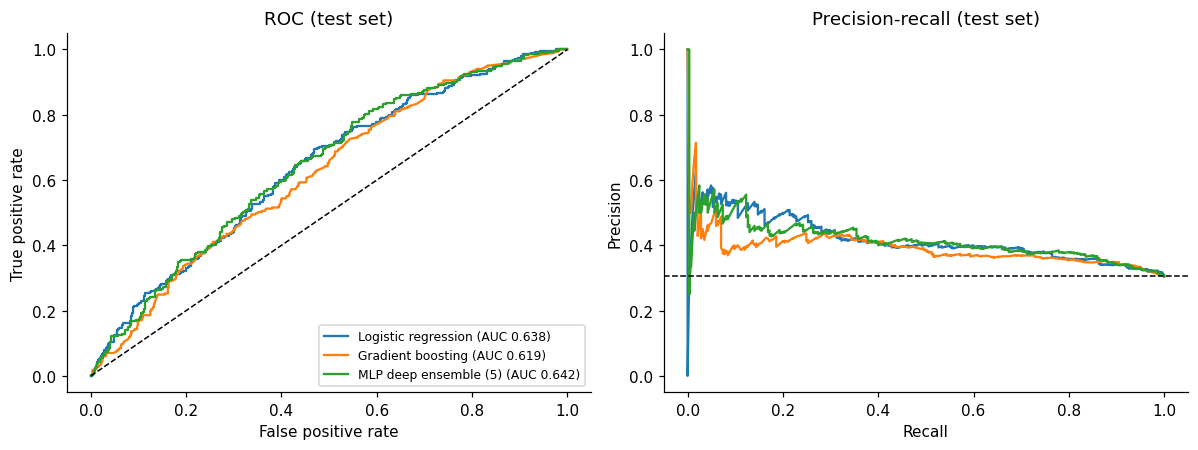

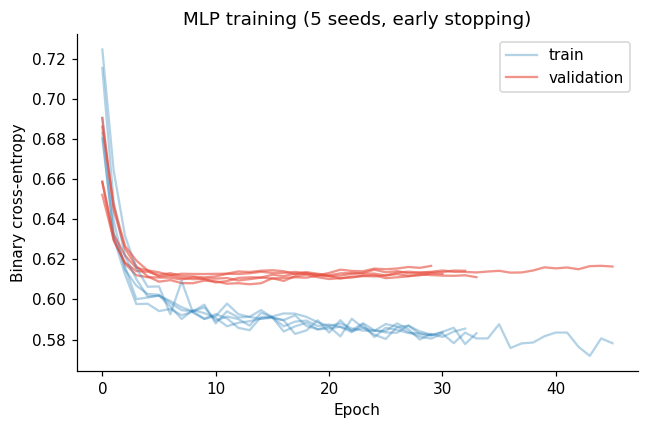

In [56]:
# Figure 5: ROC and precision-recall curves | Figure 6: MLP training curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p in p_te.items():
    f, t, _ = roc_curve(yte, p); ax[0].plot(f, t, label=f"{name} (AUC {roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC (test set)"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].axhline(yte.mean(), color="k", ls="--", lw=1); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall (test set)")
plt.tight_layout(); plt.savefig("PIC/05_roc_pr_curves.png"); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
for s, h in enumerate(hists):
    ax.plot([a for a, _ in h], color="#2980b9", alpha=0.35, label="train" if s == 0 else None)
    ax.plot([b for _, b in h], color="#e74c3c", alpha=0.6, label="validation" if s == 0 else None)
ax.set_xlabel("Epoch"); ax.set_ylabel("Binary cross-entropy"); ax.set_title("MLP training (5 seeds, early stopping)")
ax.legend(); plt.tight_layout(); plt.savefig("PIC/06_mlp_training_curves.png"); plt.show()


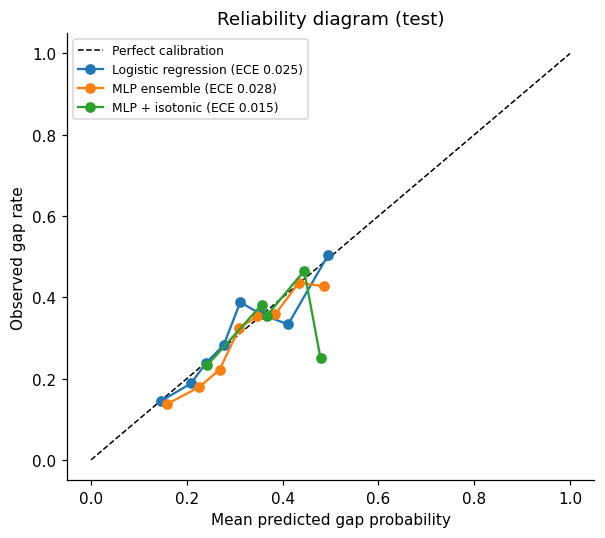

Brier: MLP 0.2014 -> MLP + isotonic 0.2016


In [57]:
# Calibration: do predicted risks match observed frequencies?  (isotonic recalibration fitted on VALIDATION only)
iso = IsotonicRegression(out_of_bounds="clip").fit(p_val_nn, yva)
p_te_nn_cal = iso.predict(p_te_nn)

def reliability(y, p, bins=8):
    q_ = pd.qcut(p, bins, duplicates="drop")
    g = pd.DataFrame({"y": y, "p": p, "b": q_}).groupby("b", observed=True).agg(obs=("y", "mean"), pred=("p", "mean"), n=("y", "size"))
    ece = float((g.n * (g.obs - g.pred).abs()).sum() / g.n.sum())
    return g, ece

fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
for name, p in [("Logistic regression", p_te["Logistic regression"]), ("MLP ensemble", p_te_nn), ("MLP + isotonic", p_te_nn_cal)]:
    g, ece = reliability(yte, p)
    ax.plot(g.pred, g.obs, "o-", label=f"{name} (ECE {ece:.3f})")
ax.set_xlabel("Mean predicted gap probability"); ax.set_ylabel("Observed gap rate"); ax.set_title("Reliability diagram (test)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("PIC/07_calibration.png"); plt.show()
print(f"Brier: MLP {brier_score_loss(yte, p_te_nn):.4f} -> MLP + isotonic {brier_score_loss(yte, p_te_nn_cal):.4f}")


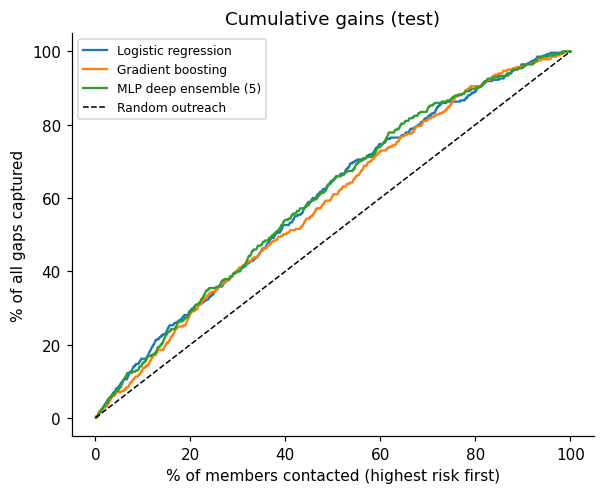

Contact top 10% by MLP risk -> captures 14.7% of all gaps (random outreach: 10%); lift = 1.47x
Contact top 20% by MLP risk -> captures 29.1% of all gaps (random outreach: 20%); lift = 1.46x
Contact top 30% by MLP risk -> captures 40.0% of all gaps (random outreach: 30%); lift = 1.33x


In [58]:
# Decision utility: cumulative gains. If outreach reaches only the top k% highest-risk members, what share of all gaps is captured?
def gains(y, p):
    o = np.argsort(-p); cum = np.cumsum(y[o]) / y.sum(); frac = np.arange(1, len(y) + 1) / len(y)
    return frac, cum

fig, ax = plt.subplots(figsize=(5.6, 4.6))
for name, p in p_te.items():
    f, c = gains(yte, p); ax.plot(f * 100, c * 100, label=name)
ax.plot([0, 100], [0, 100], "k--", lw=1, label="Random outreach")
ax.set_xlabel("% of members contacted (highest risk first)"); ax.set_ylabel("% of all gaps captured")
ax.set_title("Cumulative gains (test)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("PIC/08_cumulative_gains.png"); plt.show()

f, c = gains(yte, p_te_nn)
for k in (0.10, 0.20, 0.30):
    i = int(k * len(yte)) - 1
    print(f"Contact top {k:.0%} by MLP risk -> captures {c[i]:.1%} of all gaps (random outreach: {k:.0%}); lift = {c[i] / k:.2f}x")


                  n  observed gap rate  mean predicted  calibration gap (pred-obs)    AUC  sensitivity (flagged | gap)  flag rate | no gap
race_ethnicity                                                                                                                            
Asian            61              0.164           0.316                       0.152  0.694                        0.300               0.235
Black           208              0.389           0.348                      -0.042  0.629                        0.481               0.323
Hispanic        191              0.340           0.312                      -0.028  0.686                        0.354               0.175
Other            39              0.282           0.338                       0.056  0.571                        0.273               0.286
White           436              0.271           0.324                       0.053  0.627                        0.390               0.264

              n  observed 

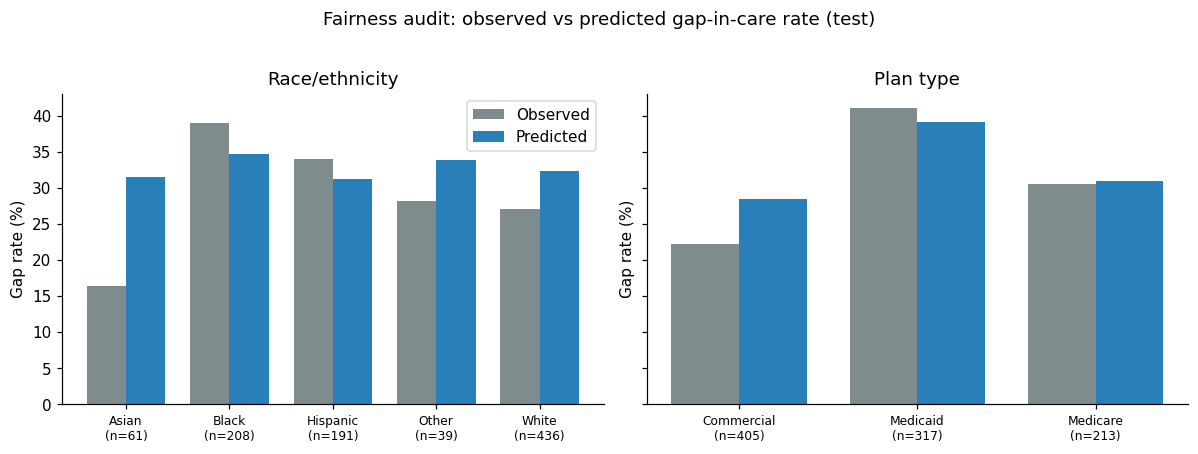

In [59]:
# Fairness audit by race/ethnicity and plan type (race was NOT a model input).
# Operating point: flag the top 30% highest-risk members for outreach.
thr = np.quantile(p_te_nn, 0.70)
audit = test_df[["race_ethnicity", "plan_type"]].copy()
audit["y"] = yte; audit["p"] = p_te_nn; audit["flag"] = (audit.p >= thr).astype(int)

def audit_table(col):
    rows = []
    for g, d in audit.groupby(col):
        auc = roc_auc_score(d.y, d.p) if d.y.nunique() == 2 else np.nan
        pos, neg = d[d.y == 1], d[d.y == 0]
        rows.append({col: g, "n": len(d), "observed gap rate": d.y.mean(), "mean predicted": d.p.mean(),
                     "calibration gap (pred-obs)": d.p.mean() - d.y.mean(), "AUC": auc,
                     "sensitivity (flagged | gap)": pos.flag.mean() if len(pos) else np.nan,
                     "flag rate | no gap": neg.flag.mean() if len(neg) else np.nan})
    return pd.DataFrame(rows).set_index(col)

aud_race, aud_plan = audit_table("race_ethnicity"), audit_table("plan_type")
print(aud_race.round(3).to_string()); print(); print(aud_plan.round(3).to_string())
print("\nNote: subgroup n is small for some categories; treat those estimates as indicative, not conclusive.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, tab, title in [(ax[0], aud_race, "Race/ethnicity"), (ax[1], aud_plan, "Plan type")]:
    x = np.arange(len(tab)); w = 0.38
    a.bar(x - w / 2, tab["observed gap rate"] * 100, w, label="Observed", color="#7f8c8d")
    a.bar(x + w / 2, tab["mean predicted"] * 100, w, label="Predicted", color="#2980b9")
    a.set_xticks(x); a.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(tab.index, tab.n)], fontsize=8)
    a.set_title(title); a.set_ylabel("Gap rate (%)")
ax[0].legend(); plt.suptitle("Fairness audit: observed vs predicted gap-in-care rate (test)", y=1.02)
plt.tight_layout(); plt.savefig("PIC/09_fairness_audit.png", bbox_inches="tight"); plt.show()


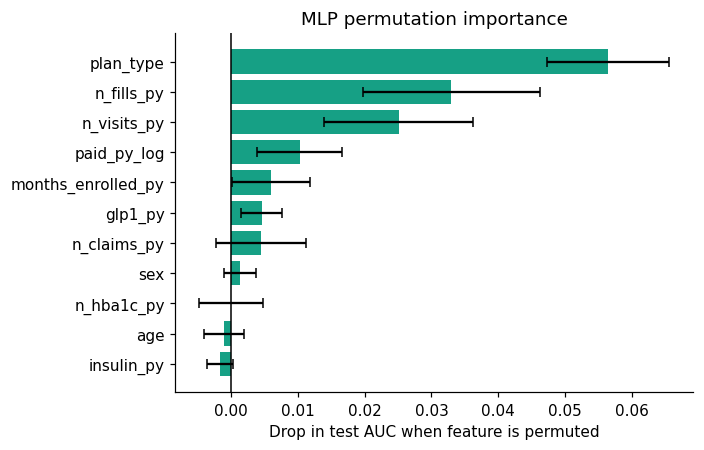

           feature  auc_drop     sd
         plan_type    0.0565 0.0091
        n_fills_py    0.0330 0.0132
       n_visits_py    0.0251 0.0111
       paid_py_log    0.0103 0.0063
months_enrolled_py    0.0060 0.0059
           glp1_py    0.0046 0.0031
       n_claims_py    0.0045 0.0067
               sex    0.0013 0.0024
        n_hba1c_py   -0.0000 0.0048
               age   -0.0010 0.0030
        insulin_py   -0.0016 0.0019


In [60]:
# Permutation importance on the raw columns (drop in test AUC when a column is shuffled)
def predict_raw(df):
    return nn_predict(prep.transform(df[model_feats]))

base_auc = roc_auc_score(yte, predict_raw(test_df))
r = np.random.default_rng(5); imp = []
for col in model_feats:
    drops = []
    for _ in range(15):
        d = test_df.copy(); d[col] = r.permutation(d[col].values)
        drops.append(base_auc - roc_auc_score(yte, predict_raw(d)))
    imp.append((col, np.mean(drops), np.std(drops)))
imp = pd.DataFrame(imp, columns=["feature", "auc_drop", "sd"]).sort_values("auc_drop")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(imp.feature, imp.auc_drop, xerr=imp.sd, color="#16a085", capsize=3)
ax.axvline(0, color="k", lw=1); ax.set_xlabel("Drop in test AUC when feature is permuted")
ax.set_title("MLP permutation importance")
plt.tight_layout(); plt.savefig("PIC/10_permutation_importance.png"); plt.show()
print(imp.sort_values("auc_drop", ascending=False).round(4).to_string(index=False))


## 8. Documentation

### Measure specification
| Element | Definition |
|---|---|
| Measure | HbA1c testing, members with diabetes (HEDIS-style, simplified) |
| Measurement years | 2023, 2024 |
| Age | 18-75 as of the measurement year |
| Diabetes identification | 2 or more claims with ICD-10 E11.x on different dates in the year, or at least one diabetes drug fill (metformin, insulin, GLP-1) |
| Continuous enrollment | At least 11 months enrolled and no coverage gap longer than 45 days |
| Numerator | At least one claim with CPT 83036 in the measurement year |
| Rate | Numerator / denominator, with Wilson 95% CI |

### Data dictionary
| Table | Key fields | Notes |
|---|---|---|
| members | member_id, birth_year, sex, race_ethnicity | One row per person |
| eligibility | member_id, year, months_enrolled, max_gap_days, plan_type | One row per member-year |
| medical_claims | claim_id, member_id, service_date, dx_code, cpt_code, paid_amount | Raw, contains defects |
| pharmacy_claims | member_id, fill_date, drug_class | Used for diabetes identification |
| survey | member_id, plan_type, plan_rating | CAHPS-style 0-10, 3,000 respondents |

### Model card: gap-in-care risk model
| Element | Detail |
|---|---|
| Intended use | Rank diabetic members by risk of missing an HbA1c test, to prioritize outreach. Not for coverage, eligibility, or clinical decisions about an individual |
| Target | No CPT 83036 claim in 2024 |
| Inputs | 2023 utilization, drug classes, prior-year enrollment, age, sex, plan type. Race/ethnicity excluded |
| Training data | Synthetic; 60/20/20 train/validation/test split, preprocessing fit on train only |
| Models | Logistic regression, histogram gradient boosting, PyTorch MLP (64-32, BatchNorm, Dropout 0.3, AdamW, early stopping) averaged over 5 seeds |
| Evaluation | ROC-AUC with bootstrap CI, PR-AUC, Brier, calibration, cumulative gains, subgroup audit |
| Known limits | Synthetic signal; small subgroups give wide uncertainty; a single random split rather than temporal validation; observed gaps reflect access as well as behavior |
| Governance | Audit calibration and error rates by subgroup before any deployment; recheck after each measurement year |

### Assumptions and limitations
- Data are synthetic. Effects (for example the Medicaid and race gaps) were built into the generator, so the analysis recovers known patterns by design.
- Claims with defects (duplicates, missing IDs, negative payments, impossible dates, orphans) are excluded in the `claims_clean` view and counted in the QC log. In practice these would be escalated to the data owner first.
- Race/ethnicity is a single category. The logistic model adjusts for observed variables only and does not prove causation.
- A hidden member-level engagement trait was added to the generator so that prior-year behavior is informative. The neural-network results therefore show how the methods behave, not real-world model performance.
- Seed fixed (`default_rng(2024)`, torch seeds 0-4), so results reproduce closely; GPU runs may differ slightly.

### Equivalent SAS (for reference)
```sas
/* Rates and chi-square by group */
proc freq data=d24;
    tables race_ethnicity*hba1c_test / chisq nocol nopercent;
run;

/* Adjusted logistic regression with odds ratios */
proc logistic data=d24;
    class sex(ref='F') plan_type(ref='Commercial') race_ethnicity(ref='White') / param=ref;
    model hba1c_test(event='1') = age_10yr sex plan_type race_ethnicity;
run;
```
